# **Introduction**

This project explores supermarket transaction data using Python and Google Colab. The objective is to understand sales performance, customer purchasing behaviour, product categories, and payment methods through exploratory data analysis.

The analysis uses descriptive statistics and data visualisations to identify patterns that could support business decisions, such as improving product planning and understanding customer preferences.

# **Import Libraries and Load Dataset**

Python libraries provide tools for data manipulation, statistical analysis, and visualization. The following libraries are used in this project:
- Pandas: Used for loading, cleaning, and analyzing datasets.
- NumPy: Used for numerical calculations and statistical operations.
- Matplotlib: Used to create graphs and visualizations.
- Seaborn: Used to create statistical visualizations and explore relationships between variables.

In [153]:
import pandas as pd

df = pd.read_csv('/content/SuperMarket_Analysis_Preprocessing_Practice.csv')

df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,NaN,7.0,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5.0,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,NaN
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,NaN,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8.0,23.2880,489.0480,1/27/2019,8:33:00 PM,NaN,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,NaN,Female,Sports and travel,86.31,7.0,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [154]:
df.shape

(1005, 17)

In [155]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [156]:
df.columns

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Sales', 'Date',
       'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income',
       'Rating'],
      dtype='object')

In [157]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1005 non-null   object 
 1   Branch                   1005 non-null   object 
 2   City                     1005 non-null   object 
 3   Customer type            1002 non-null   object 
 4   Gender                   1002 non-null   object 
 5   Product line             1001 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1001 non-null   float64
 8   Tax 5%                   1005 non-null   float64
 9   Sales                    1005 non-null   float64
 10  Date                     1005 non-null   object 
 11  Time                     1005 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1005 non-null   float64
 14  gross margin percentage 

# **Data Understanding**

The dataset contains supermarket transaction records. Before performing statistical analysis, it is important to understand its size, column names, and data types.

The df.shape command identifies the number of rows and columns, df.columns lists the features, and df.info() displays the data types and non-null counts.

The dataset contains 1,000 rows and 17 columns, including categorical features such as City and Product line, and numerical features such as Unit price and Sales.

In [158]:
df.describe()

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1001.000000,1005.000000,1005.000000,1005.000000,1.005000e+03,1005.000000,999.000000
mean,55.657870,5.495504,15.336377,322.063919,306.727542,4.761905e+00,15.336377,6.974274
std,26.519132,2.929203,11.698239,245.663013,233.964774,6.220344e-14,11.698239,1.719279
min,10.080000,1.000000,0.508500,10.678500,10.170000,4.761905e+00,0.508500,4.000000
25%,32.777500,3.000000,5.832000,122.472000,116.640000,4.761905e+00,5.832000,5.500000
50%,55.055000,5.000000,12.060000,253.260000,241.200000,4.761905e+00,12.060000,7.000000
75%,77.935000,8.000000,22.428000,470.988000,448.560000,4.761905e+00,22.428000,8.500000
max,99.960000,10.000000,49.650000,1042.650000,993.000000,4.761905e+00,49.650000,10.000000


In [159]:
df.isnull().sum()

,0
Invoice ID,0
Branch,0
City,0
Customer type,3
Gender,3
Product line,4
Unit price,5
Quantity,4
Tax 5%,0
Sales,0


# **Missing Value**

The results identified 30 missing values across seven columns: Customer type (3), Gender (3), Product line (4), Unit price (5), Quantity (4), Payment (5), and Rating (6).

These missing values were intentionally introduced into a copy of the original dataset to demonstrate data preprocessing techniques. Numerical and categorical missing values will be handled using appropriate replacement methods.

# **Fill the missing values**

In [160]:

#using median
df['Unit price'] = df['Unit price'].fillna(df['Unit price'].median())
df['Quantity'] = df['Quantity'].fillna(df['Quantity'].median())
df['Rating'] = df['Rating'].fillna(df['Rating'].median())

#using mode
df['Customer type'] = df['Customer type'].fillna(df['Customer type'].mode()[0])
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
df['Product line'] = df['Product line'].fillna(df['Product line'].mode()[0])
df['Payment'] = df['Payment'].fillna(df['Payment'].mode()[0])

# after cleaning
df.isnull().sum()


,0
Invoice ID,0
Branch,0
City,0
Customer type,0
Gender,0
Product line,0
Unit price,0
Quantity,0
Tax 5%,0
Sales,0


# **Duplicate Records**


The results identified five completely duplicated records. These duplicate records were deliberately introduced for the purpose of demonstrating data cleaning.

Duplicate transactions should be removed before analysis to prevent the same transaction from being counted more than once.

# **Remove duplicate records**

In [161]:
df = df.drop_duplicates()

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

Dataset shape: (1000, 17)
Missing values: 0
Duplicates: 0


In [162]:
df.duplicated().sum()

np.int64(0)

# **Data Cleaning Results**


The modified dataset initially contained 1,005 records, including five duplicate records and 30 missing values.

Missing numerical values were replaced using the median, while missing categorical values were replaced using the mode.

After preprocessing, the dataset contained 1,000 records, with no missing values or duplicate records remaining.

The missing values and duplicates were intentionally introduced for the purpose of demonstrating data preprocessing techniques.


In [163]:
df.describe()

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.000000
mean,55.652065,5.505000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.976900
std,26.444889,2.921731,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.713538
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.000000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.500000
50%,55.055000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.000000
75%,77.772500,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.500000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.000000


In [164]:
df

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,55.055,7.0,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.280,5.0,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,7.0
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.330,5.0,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.220,8.0,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.310,7.0,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,Giza,Naypyitaw,Normal,Male,Health and beauty,40.350,1.0,2.0175,42.3675,1/29/2019,1:46:00 PM,Ewallet,40.35,4.761905,2.0175,6.2
996,303-96-2227,Cairo,Mandalay,Normal,Female,Home and lifestyle,97.380,10.0,48.6900,1022.4900,3/2/2019,5:16:00 PM,Ewallet,973.80,4.761905,48.6900,4.4
997,727-02-1313,Alex,Yangon,Member,Male,Food and beverages,31.840,1.0,1.5920,33.4320,2/9/2019,1:22:00 PM,Cash,31.84,4.761905,1.5920,7.7
998,347-56-2442,Alex,Yangon,Normal,Male,Home and lifestyle,65.820,1.0,3.2910,69.1110,2/22/2019,3:33:00 PM,Cash,65.82,4.761905,3.2910,4.1


This provides a summary of the numerical variables, including the mean, standard deviation, minimum, maximum, and quartiles.

These statistics help understand the distribution of the cleaned supermarket sales data and provide a basis for further analysis and visualizations.

# **Identify categorical and numerical variables**

## **Variable Identification**

The dataset contains categorical and numerical variables. Categorical variables represent groups or classifications, while numerical variables represent measurable quantities.

Identifying these variables is important because different statistical methods and visualizations are appropriate for different data types.

In [165]:
categorical_columns = df.select_dtypes(include=['object']).columns

print(categorical_columns)


Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Date', 'Time', 'Payment'],
      dtype='object')


## **Numerical Variable Identification**

Numerical variables represent measurable quantities that can be analyzed using statistical methods. The supermarket dataset includes variables such as Unit price, Quantity, Sales, and Rating.

Identifying numerical variables allows us to calculate descriptive statistics and examine their distributions.

In [166]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print(numerical_columns)


Index(['Unit price', 'Quantity', 'Tax 5%', 'Sales', 'cogs',
       'gross margin percentage', 'gross income', 'Rating'],
      dtype='object')


The dataset contains eight numerical variables. These include sales-related measurements such as Unit price, Sales, Tax 5%, and gross income, as well as Quantity and customer Rating.

These variables can be analyzed using measures such as mean, median, standard deviation, minimum, and maximum. Their distributions can also be explored using histograms and box plots.

# **Data Visualizations**
Data visualization is an important part of exploratory data analysis. It helps identify patterns, trends, and distributions within a dataset.

In this section, different visualizations are used to examine supermarket sales, customer behaviour, and product performance.

## **Distribution of Sales**

A histogram is used to visualize the distribution of supermarket transaction values. It shows how frequently different sales amounts occur and helps identify the most common transaction ranges, variation, and possible skewness.

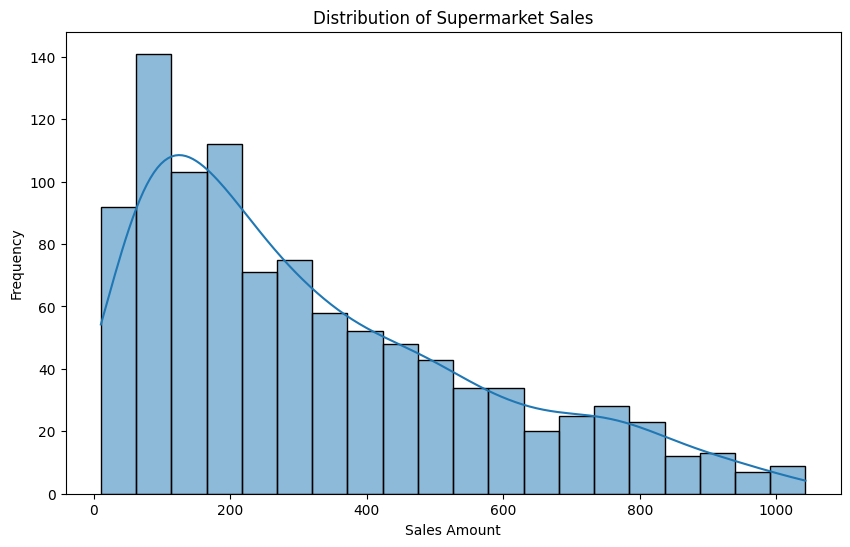

In [167]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='Sales', bins=20, kde=True)

plt.title('Distribution of Supermarket Sales')
plt.xlabel('Sales Amount')
plt.ylabel('Frequency')

plt.show()

## **Sales Distribution**

The histogram illustrates the distribution of supermarket transaction values. The average sales amount is approximately 322.97, while the median is approximately 253.85.

Since the mean is greater than the median, the sales distribution suggests positive skewness, indicating that some higher-value transactions increase the overall average.

The graph helps identify customer spending patterns and understand how transaction values vary across the supermarket.

## **Sales by Product Line**

A bar chart is used to compare total sales across different product lines. This visualization helps identify which product categories generate the highest and lowest sales revenue.

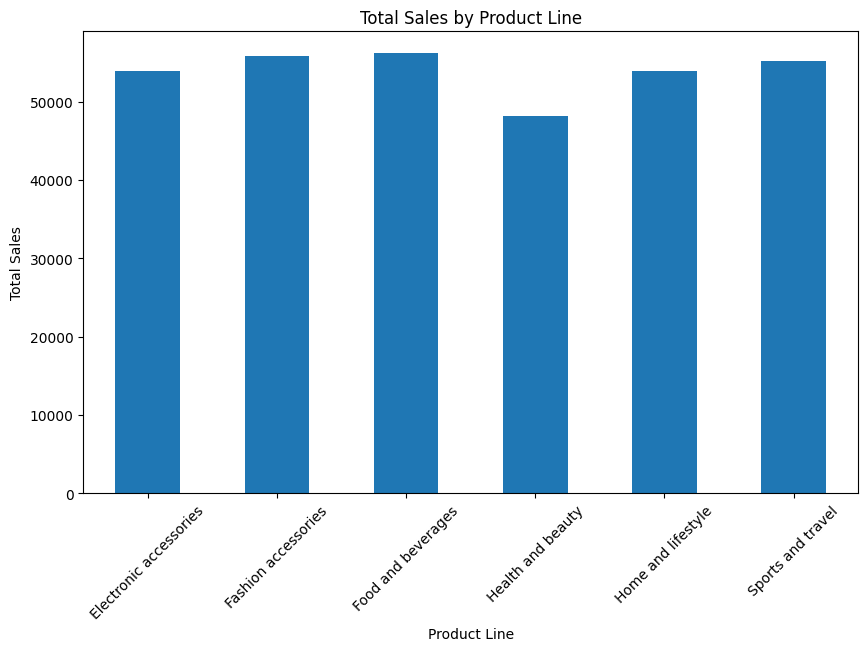

In [168]:
product_sales = df.groupby('Product line')['Sales'].sum()

product_sales.plot(kind='bar', figsize=(10, 6))

plt.title('Total Sales by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

In [169]:
product_sales.sort_values(ascending=False)

,Sales
Product line,
Food and beverages,56144.8440
Fashion accessories,55766.2140
Sports and travel,55122.8265
Electronic accessories,53903.8395
Home and lifestyle,53861.9130
Health and beauty,48167.1120


## **Sales by Product Line**



The bar chart compares total sales revenue across six supermarket product categories.

Food and beverages generated the highest total sales revenue of approximately 56,144.84, followed by Fashion accessories with 55,766.21.

Health and beauty recorded the lowest total sales revenue of approximately 48,167.11.


# **Sales by City**

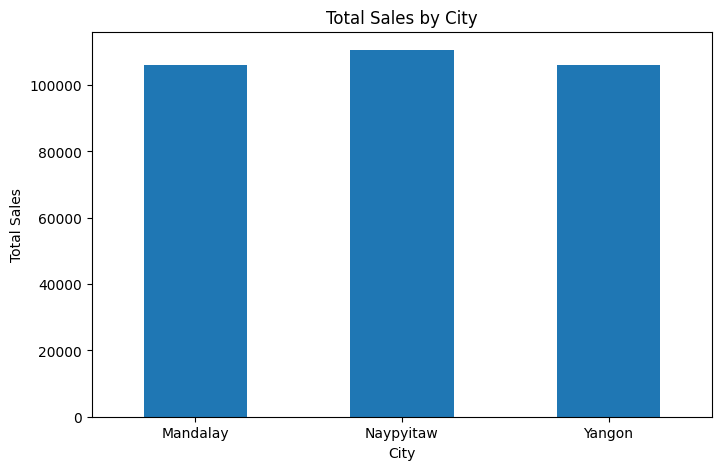

In [170]:
city_sales = df.groupby('City')['Sales'].sum()

city_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Total Sales by City')
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.show()

## **Sales by City**

The bar chart compares total sales revenue across three supermarket locations.

Naypyitaw generated the highest sales, approximately 110,568.71, followed by Yangon with 106,200.37. Mandalay recorded the lowest sales, approximately 106,197.67.

Although Naypyitaw generated the most revenue, the sales figures for Yangon and Mandalay were almost identical. This comparison helps the business evaluate revenue performance across its locations.

# **Distribution of Payment Methods**



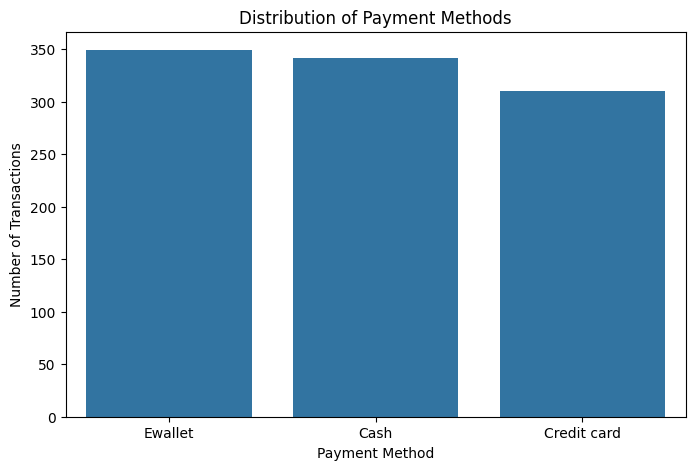

In [171]:
plt.figure(figsize=(8, 5))

sns.countplot(x='Payment', data=df)

plt.title('Distribution of Payment Methods')
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')

plt.show()

## **Payment Methods**

The count plot compares the frequency of different payment methods used by supermarket customers.

Ewallet was the most frequently used payment method, with 349 transactions, followed closely by Cash with 341 transactions. Credit card was the least frequently used method, with 310 transactions.

The relatively small differences suggest that customers use all three payment methods regularly.

# **Customer Ratings Distribution**



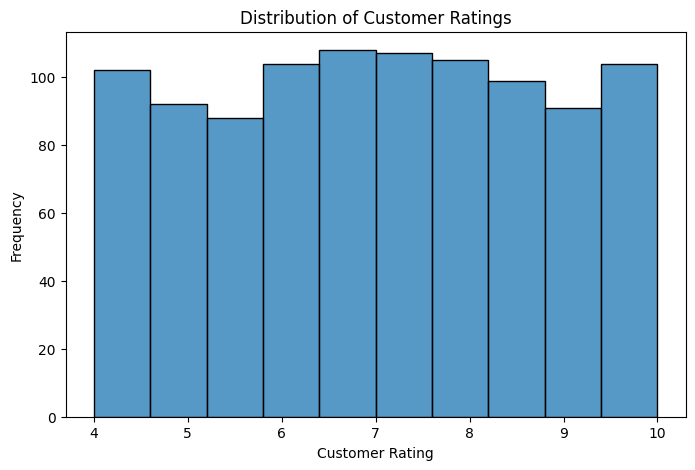

In [145]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Rating'], bins=10)

plt.title('Distribution of Customer Ratings')
plt.xlabel('Customer Rating')
plt.ylabel('Frequency')

plt.show()

## **Customer Ratings**

The histogram shows the distribution of customer ratings recorded in the supermarket dataset.

The average customer rating is approximately **6.97 out of 10**. The graph can be used to identify the most common rating ranges and understand how customer feedback varies.

These findings can help the supermarket investigate customer satisfaction, although ratings alone do not explain the reasons behind customers' experiences.

In [146]:
print(df.groupby('City')['Sales'].sum().sort_values(ascending=False))

print(df['Payment'].value_counts())

City
Naypyitaw    110568.7065
Yangon       106200.3705
Mandalay     106197.6720
Name: Sales, dtype: float64
Payment
Ewallet        349
Cash           341
Credit card    310
Name: count, dtype: int64


# **Box Plot of Sales**

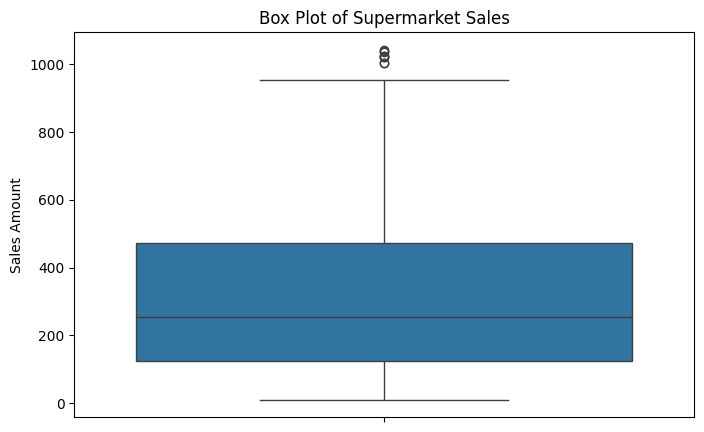

In [147]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Sales'])

plt.title('Box Plot of Supermarket Sales')
plt.ylabel('Sales Amount')

plt.show()

## **Box Plot of Sales**

The box plot shows the variation in supermarket transaction values. The median sales amount is approximately 253.85, while the middle 50% of transactions fall between approximately 124.42 and 471.35.

# **Relationship Analysis**

Relationship analysis is used to examine how different variables are associated with each other. It helps identify patterns and correlations within the dataset.


## **Relationship Between Unit Price and Sales**

The correlation coefficient is approximately 0.630, indicating a moderately strong positive linear relationship between Unit price and Sales.

This suggests that higher-priced products tend to be associated with higher transaction values. However, total sales also depend on the quantity purchased.

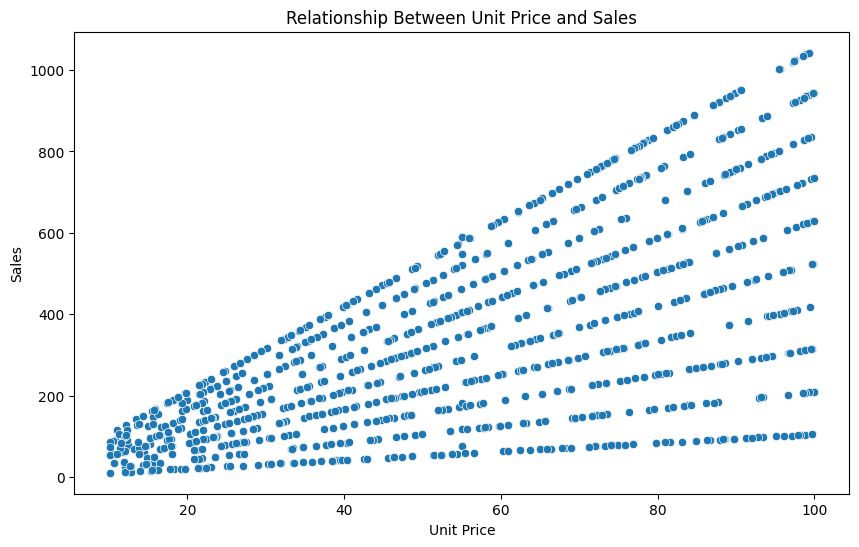

In [148]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x='Unit price', y='Sales', data=df)

plt.title('Relationship Between Unit Price and Sales')
plt.xlabel('Unit Price')
plt.ylabel('Sales')

plt.show()

In [149]:
df['Unit price'].corr(df['Sales'])

np.float64(0.6317519740739731)

The correlation coefficient is approximately **0.632**, indicating a moderately strong positive linear relationship between Unit price and Sales.



# **Relationship Between Product Line and Sales**

A box plot is used to compare transaction sales distributions across different product categories. It displays the median, quartiles, spread, and potential outliers for each product line.


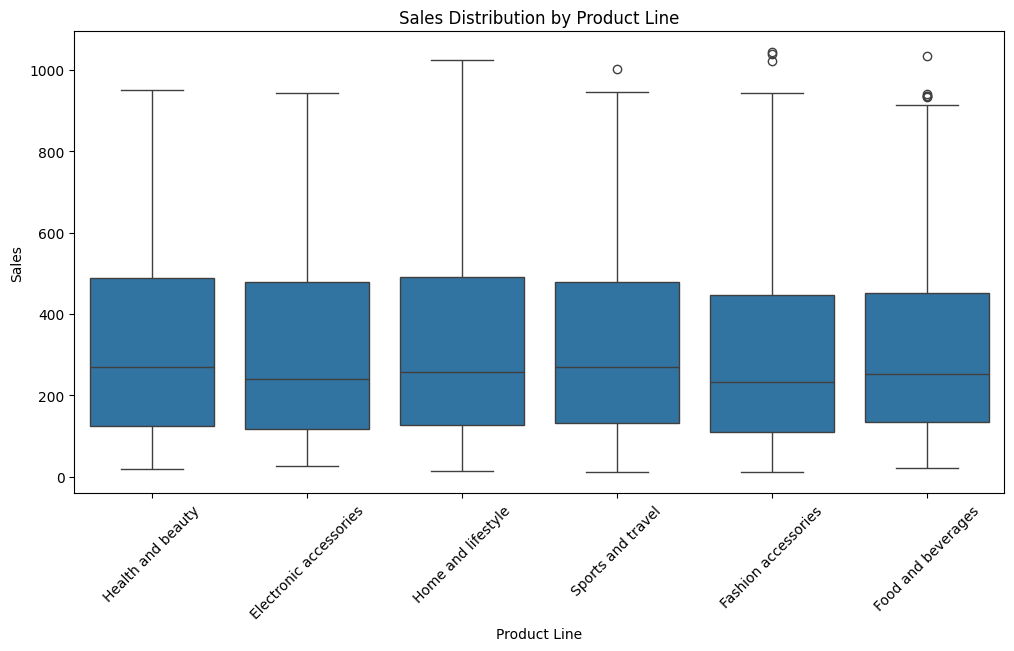

In [150]:
plt.figure(figsize=(12, 6))

sns.boxplot(x='Product line', y='Sales', data=df)

plt.title('Sales Distribution by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Sales')
plt.xticks(rotation=45)

plt.show()

The box plot compares the distribution of transaction sales across different product lines.

Differences in the median and spread of sales indicate that transaction values vary between product categories. Potential outliers represent transactions with unusually high sales amounts compared with other transactions in the same category.

# **Correlation Heatmap**
## **Correlation Analysis of Numerical Variables**

Correlation analysis measures the strength and direction of linear relationships between numerical variables.

A heatmap is used to visualize correlation coefficients. Positive values indicate that variables tend to increase together, while negative values indicate that one variable tends to decrease as the other increases.

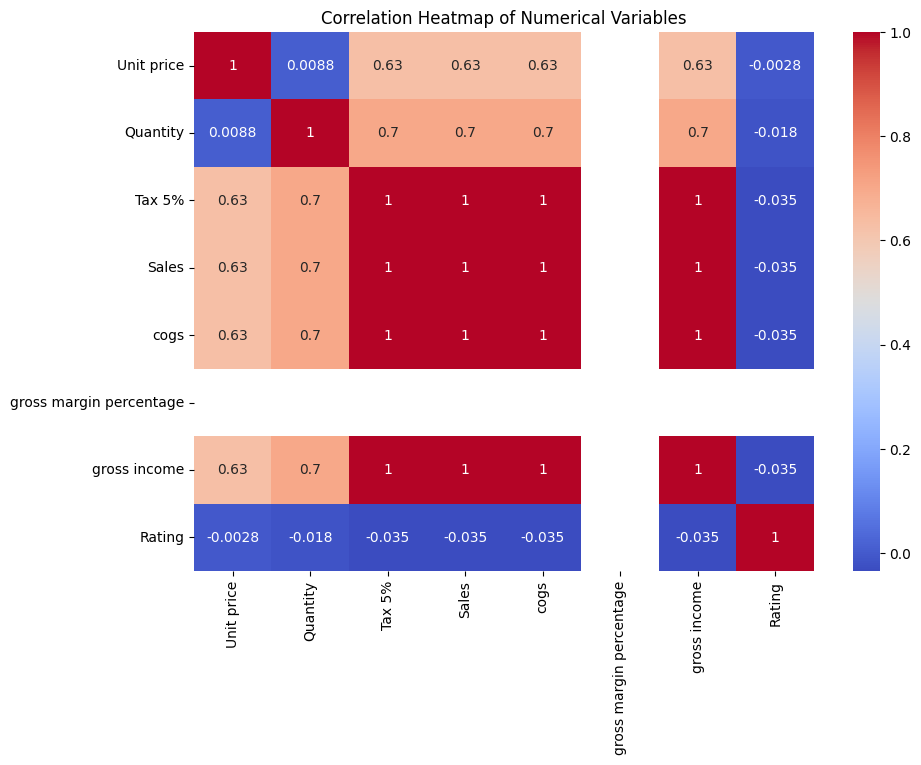

In [151]:
plt.figure(figsize=(10, 7))

correlation = df.select_dtypes(include=['int64', 'float64']).corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap of Numerical Variables')

plt.show()

The heatmap displays correlations between numerical variables in the supermarket dataset.

Sales, Tax 5%, cogs, and gross income are expected to show very strong positive correlations because they are mathematically related.

Other variables, such as Unit price, Quantity, and Rating, can be examined to identify additional relationships.

Strong correlations do not necessarily indicate that one variable causes changes in another.

# **Relationship Between City and Customer Ratings**

City
Mandalay     6.825602
Naypyitaw    7.067683
Yangon       7.037059
Name: Rating, dtype: float64


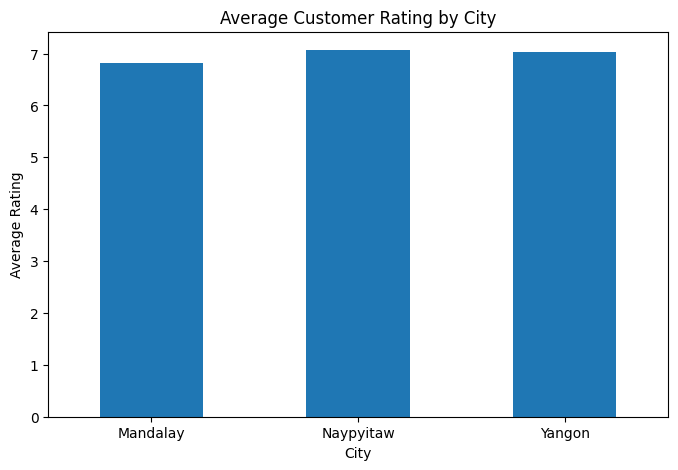

In [152]:
city_rating = df.groupby('City')['Rating'].mean()

print(city_rating)

city_rating.plot(kind='bar', figsize=(8, 5))

plt.title('Average Customer Rating by City')
plt.xlabel('City')
plt.ylabel('Average Rating')
plt.xticks(rotation=0)

plt.show()



The bar chart compares average customer ratings across the three supermarket locations.

Naypyitaw recorded the highest average customer rating of approximately 7.07, followed by Yangon with 7.04. Mandalay recorded the lowest average rating of 6.83.

These results indicate small differences in customer feedback between locations. Further analysis would be needed to determine whether these differences are meaningful.

# **Key Findings and Business Recommendations**

## **Key Findings**

The exploratory data analysis of 1,000 supermarket transactions identified several important findings.

**1. Sales Performance:** The average transaction value was approximately 322.97, while the median was approximately 253.85, indicating a positively skewed sales distribution.

**2. Product Performance:** Food and beverages generated the highest total sales of approximately 56,144.84, while Health and beauty recorded the lowest at 48,167.11.

**3. Branch Performance:** Naypyitaw generated the highest sales revenue of approximately 110,568.71. Yangon and Mandalay recorded similar total sales of approximately 106,200.

**4. Customer Payment Preferences:** Ewallet was the most frequently used payment method with 349 transactions, followed by Cash with 341 and Credit card with 310.

**5. Customer Ratings:** Naypyitaw recorded the highest average customer rating of approximately 7.07, while Mandalay recorded the lowest at approximately 6.83.

**6. Relationship Analysis:** The correlation between Unit price and Sales was approximately 0.632, indicating a moderately strong positive linear relationship.

## **Business Recommendations**

Based on the exploratory data analysis, the following recommendations can be considered:

**1. Improve Inventory Planning:** Food and beverages generated the highest sales revenue. The supermarket should review demand and stock availability for this product category to support inventory decisions.

**2. Review Lower-Performing Categories:** Health and beauty generated the lowest total sales. The supermarket could investigate customer demand, pricing, and promotional opportunities for this category.

**3. Evaluate Branch Performance:** Naypyitaw generated the highest sales revenue and average customer rating. The supermarket could compare operating practices across branches to identify opportunities for improvement.

**4. Maintain Multiple Payment Options:** Ewallet, Cash, and Credit card were all used frequently. The supermarket should continue supporting all three methods to accommodate customer preferences.

**5. Investigate Customer Feedback:** Mandalay recorded a slightly lower average customer rating than the other locations. Further customer feedback analysis could help identify potential areas for service improvement.

# **Limitations**

The supermarket sales dataset was modified by intentionally introducing missing values and duplicate records to demonstrate data preprocessing techniques.

Missing numerical values were replaced using the median, while missing categorical values were replaced using the mode. Although these methods helped clean the dataset, the replaced values may not exactly represent the original transactions.

Additionally, replacing missing values in Unit price and Quantity does not automatically update related financial variables such as Sales and cogs. Therefore, some relationships in the modified dataset may not be completely accurate.

Despite these limitations, the dataset remains useful for demonstrating data cleaning, exploratory data analysis, and visualization techniques.

# **Conclusion**

This project analysed 1,000 supermarket transactions using Python and exploratory data analysis techniques. Pandas, NumPy, Matplotlib, and Seaborn were used to explore the dataset, calculate descriptive statistics, and create visualizations.

The dataset was also used to demonstrate data preprocessing techniques. Missing values and duplicate records were intentionally introduced, then handled using median and mode imputation and duplicate removal.

The analysis identified differences in revenue across product categories and supermarket locations. Food and beverages generated the highest total sales, while Naypyitaw recorded the highest branch revenue and average customer rating.

A moderately strong positive correlation was identified between unit price and transaction sales. The results also showed that Ewallet, Cash, and Credit card were commonly used payment methods.

Overall, the project demonstrates how exploratory data analysis and preprocessing can support business understanding and identify opportunities for further investigation.